2.  Classify the email using the binary classification method. Email Spam detection has two 
states: a) Normal State – Not Spam, b) Abnormal State – Spam. Use K-Nearest Neighbors and 
Support Vector Machine for classification. Analyze their performance. 
Dataset link: The emails.csv dataset on the Kaggle 
https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv('emails.csv')

print("First 5 records:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nMissing Values:", df.isnull().sum().sum())

print("\nEmail Class Distribution:")
print(df['Prediction'].value_counts())

First 5 records:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset Shape: (5172, 3002)

Missing Values:

In [3]:
# Remove Email ID and separate target
X = df.drop(columns=['Email No.', 'Prediction'])
y = df['Prediction']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (5172, 3000)
Target Shape: (5172,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 4137
Testing Records: 1035


In [5]:
# KNN Model
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# SVM Model
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='linear'))
])

In [6]:
# Train KNN
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

# Train SVM
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("KNN Predictions:")
print(knn_pred[:20])

print("\nSVM Predictions:")
print(svm_pred[:20])


KNN Predictions:
[0 0 1 0 1 1 0 1 0 1 0 0 1 0 0 0 1 0 1 0]

SVM Predictions:
[0 0 1 0 1 1 0 0 0 1 0 0 1 1 0 0 1 0 0 0]


In [7]:
models = {
    "KNN": knn_pred,
    "SVM": svm_pred
}

results = []

for name, pred in models.items():

    accuracy = accuracy_score(y_test, pred)
    error_rate = 1 - accuracy
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    print("\n", name, "Confusion Matrix:")
    print(confusion_matrix(y_test, pred))

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2),
        "Error Rate": round(error_rate * 100, 2),
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1 Score": round(f1 * 100, 2)
    })

print("\nPerformance Comparison:")
print(pd.DataFrame(results).to_string(index=False))


 KNN Confusion Matrix:
[[576 159]
 [ 13 287]]

 SVM Confusion Matrix:
[[709  26]
 [ 25 275]]

Performance Comparison:
Model  Accuracy  Error Rate  Precision  Recall  F1 Score
  KNN     83.38       16.62      64.35   95.67     76.94
  SVM     95.07        4.93      91.36   91.67     91.51


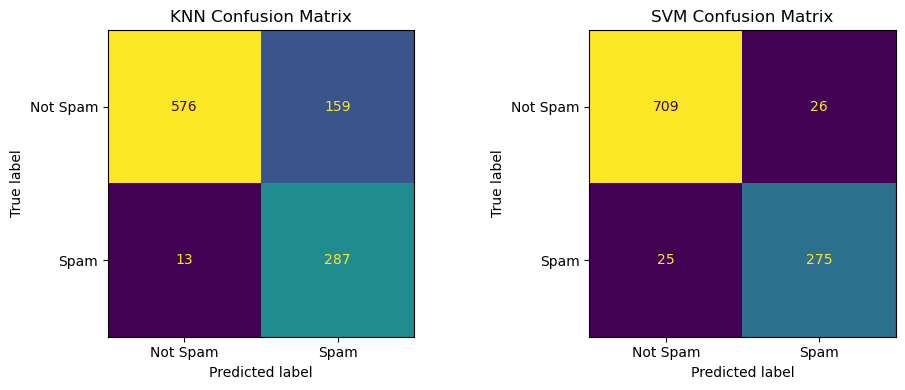

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    display_labels=['Not Spam', 'Spam'],
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("KNN Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    display_labels=['Not Spam', 'Spam'],
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("SVM Confusion Matrix")

plt.tight_layout()
plt.show()